# AI-ML Lab — Assignment 2

**1** Find a shortest path using the A* algorithm.  
**2** Implement the map-coloring problem using backtracking.

**Name:** Parth Isekar  
**Course:** AIML Lab  




## Task 1 — A* shortest-path search

### Problem formulation

- **State space:** the seven named locations in the route network.
- **Initial state:** `Main Gate`.
- **Goal state:** `AI Lab`.
- **Actions:** move along an edge to a directly connected location.
- **Step cost:** the positive illustrative cost attached to that edge.
- **Path cost,** \(g(n)\): accumulated cost from the source to node \(n\).
- **Heuristic,** \(h(n)\): Euclidean distance from node \(n\) to the selected destination.
- **A* priority:** \(f(n)=g(n)+h(n)\).

Each route edge cost is at least the Euclidean distance between its endpoints. By the triangle inequality, the heuristic is admissible (it does not overestimate the remaining route cost) and consistent for this graph. The source and destination can be changed to any node in the graph.

In [1]:
"""AI-ML Lab Assignment 2
Task 1: Shortest path using A* search
Task 2: Map coloring using backtracking as a CSP

All campus route costs below are illustrative example data, not actual campus navigation data.
Core algorithms use Python's standard library only.
"""

import heapq
import itertools
import math

# ---------------------------------------------------------------------------
# TASK 1: A* SHORTEST-PATH SEARCH
# ---------------------------------------------------------------------------

# Simplified 2-D coordinates (in metres) for an illustrative campus network.
# They let us calculate a straight-line (Euclidean) heuristic for any goal node.
POSITIONS = {
    "Main Gate": (0.0, 0.0),
    "Library": (100.0, 40.0),
    "Admin Block": (150.0, 120.0),
    "Parking": (20.0, -70.0),
    "Canteen": (220.0, 50.0),
    "Computer Block": (270.0, 130.0),
    "AI Lab": (320.0, 165.0),
}

# (location A, location B, example travel cost in metres)
ROUTE_EDGES = [
    ("Main Gate", "Library", 120),
    ("Main Gate", "Admin Block", 200),
    ("Main Gate", "Parking", 90),
    ("Library", "Canteen", 140),
    ("Library", "Computer Block", 200),
    ("Admin Block", "Canteen", 110),
    ("Admin Block", "Computer Block", 140),
    ("Parking", "Admin Block", 240),
    ("Parking", "Canteen", 250),
    ("Canteen", "Computer Block", 100),
    ("Canteen", "AI Lab", 160),
    ("Computer Block", "AI Lab", 80),
]


def build_route_graph():
    """Build an undirected weighted graph and validate the heuristic premise."""
    graph = {node: {} for node in POSITIONS}
    for node_a, node_b, cost in ROUTE_EDGES:
        if cost < 0:
            raise ValueError("Route costs must be non-negative.")
        straight_line_distance = math.dist(POSITIONS[node_a], POSITIONS[node_b])
        # This condition makes Euclidean distance an admissible and consistent heuristic.
        if cost + 1e-9 < straight_line_distance:
            raise ValueError(
                f"Edge {node_a!r}-{node_b!r} costs less than its straight-line distance; "
                "revise the example cost or heuristic."
            )
        graph[node_a][node_b] = cost
        graph[node_b][node_a] = cost
    return graph


def a_star(graph, positions, source, destination):
    """Return (path, total_cost, expanded_nodes) using A* graph search.

    The heuristic is the Euclidean distance from each node to the destination.
    Returns (None, infinity, expanded_nodes) if no route exists.
    Raises ValueError if source or destination is not in the graph.
    """
    if source not in graph:
        raise ValueError(f"Unknown source location: {source}")
    if destination not in graph:
        raise ValueError(f"Unknown destination location: {destination}")

    def heuristic(node):
        return math.dist(positions[node], positions[destination])

    counter = itertools.count()  # deterministic tie-breaker for equal priorities
    open_heap = [(heuristic(source), next(counter), source, 0)]
    g_score = {source: 0}
    parent = {source: None}
    expanded_nodes = []
    closed = set()

    while open_heap:
        _, _, current, queued_g = heapq.heappop(open_heap)

        # Ignore an older queue entry if a better path to this node was found later.
        if queued_g != g_score.get(current, math.inf):
            continue
        if current in closed:
            continue

        if current == destination:
            path = []
            node = destination
            while node is not None:
                path.append(node)
                node = parent[node]
            return path[::-1], g_score[destination], expanded_nodes

        closed.add(current)
        expanded_nodes.append(current)

        for neighbor, edge_cost in graph[current].items():
            tentative_g = g_score[current] + edge_cost
            if tentative_g < g_score.get(neighbor, math.inf):
                g_score[neighbor] = tentative_g
                parent[neighbor] = current
                f_score = tentative_g + heuristic(neighbor)
                heapq.heappush(
                    open_heap,
                    (f_score, next(counter), neighbor, tentative_g),
                )

    return None, math.inf, expanded_nodes


def dijkstra_shortest_path(graph, source, destination):
    """Independent zero-heuristic baseline used to validate the A* result."""
    if source not in graph or destination not in graph:
        raise ValueError("Source and destination must be valid graph locations.")
    # Node names are strings; a counter makes equal-cost ties deterministic.
    counter = itertools.count()
    queue = [(0, next(counter), source)]
    distance = {source: 0}
    parent = {source: None}
    visited = set()

    while queue:
        cost_so_far, _, current = heapq.heappop(queue)
        if cost_so_far != distance.get(current, math.inf):
            continue
        if current in visited:
            continue
        if current == destination:
            path = []
            node = destination
            while node is not None:
                path.append(node)
                node = parent[node]
            return path[::-1], cost_so_far
        visited.add(current)
        for neighbor, edge_cost in graph[current].items():
            candidate = cost_so_far + edge_cost
            if candidate < distance.get(neighbor, math.inf):
                distance[neighbor] = candidate
                parent[neighbor] = current
                heapq.heappush(queue, (candidate, next(counter), neighbor))
    return None, math.inf


# ---------------------------------------------------------------------------

### Run A* and independently verify its result

The code compares the selected A* route with Dijkstra's algorithm for **all 49 source–destination pairs** in the seven-node graph. Dijkstra is used only as an independent test baseline; A* is the submitted shortest-path method.

In [2]:
graph = build_route_graph()
source = "Main Gate"       # Change this to any node in POSITIONS
destination = "AI Lab"     # Change this to any node in POSITIONS
path, total_cost, expanded_nodes = a_star(graph, POSITIONS, source, destination)
baseline_path, baseline_cost = dijkstra_shortest_path(graph, source, destination)

print("TASK 1 - A* SHORTEST PATH")
print(f"Source: {source}")
print(f"Destination: {destination}")
print("Optimal path:", " -> ".join(path) if path else "No route found")
print(f"Total cost: {total_cost} metres (illustrative example data)")
print("Expanded nodes:", " -> ".join(expanded_nodes))
print(f"Expanded-node count: {len(expanded_nodes)}")
print("Dijkstra baseline:", " -> ".join(baseline_path) if baseline_path else "No route found")
print(f"Dijkstra cost: {baseline_cost} metres")
print("Selected route validation:", "PASS" if total_cost == baseline_cost else "FAIL")

pair_count = 0
for test_source in graph:
    for test_destination in graph:
        _, a_cost, _ = a_star(graph, POSITIONS, test_source, test_destination)
        _, d_cost = dijkstra_shortest_path(graph, test_source, test_destination)
        assert a_cost == d_cost, (test_source, test_destination, a_cost, d_cost)
        pair_count += 1
print(f"All-pairs A* vs Dijkstra check: PASS ({pair_count}/{pair_count})")

TASK 1 - A* SHORTEST PATH
Source: Main Gate
Destination: AI Lab
Optimal path: Main Gate -> Library -> Computer Block -> AI Lab
Total cost: 400 metres (illustrative example data)
Expanded nodes: Main Gate -> Library -> Admin Block -> Computer Block
Expanded-node count: 4
Dijkstra baseline: Main Gate -> Library -> Computer Block -> AI Lab
Dijkstra cost: 400 metres
Selected route validation: PASS
All-pairs A* vs Dijkstra check: PASS (49/49)


### How the implementation works

1. Put the start node in a min-priority queue, prioritized by \(f=g+h\).
2. Remove the node with the lowest priority. Ignore stale queue entries.
3. If it is the destination, reconstruct the route by following parent links.
4. For each neighbor, calculate the tentative \(g\)-cost. If it improves the best known cost, update its parent and push it with its new \(f\)-score.
5. If the queue becomes empty, report that no route exists.

The algorithm uses `heapq` as a priority queue, a `g_score` dictionary for best-known path costs, and a `parent` dictionary for route reconstruction. The implementation also rejects unknown source/destination names and supports changing the endpoints.

## Task 2 — Map coloring by backtracking

### Constraint-satisfaction formulation

- **Variables:** `WA`, `NT`, `SA`, `Q`, `NSW`, `V`, `T`.
- **Domain:** three colors — Red, Green, Blue.
- **Constraints:** any two adjacent regions must have different colors.
- **Goal test:** every region has a color and every adjacency constraint is satisfied.

The solver combines backtracking with three CSP heuristics/techniques: **Minimum Remaining Values (MRV)** chooses the next region with the smallest remaining domain; **degree heuristic** breaks ties by choosing the region with the most unassigned neighbors; **least-constraining value (LCV)** tries colors that restrict neighboring regions least. **Forward checking** removes a selected color from unassigned neighbors and detects empty domains before deeper recursion.

In [3]:
# TASK 2: AUSTRALIA MAP COLORING USING BACKTRACKING (CSP)
# ---------------------------------------------------------------------------

REGIONS = ["WA", "NT", "SA", "Q", "NSW", "V", "T"]
ADJACENCY = {
    "WA": {"NT", "SA"},
    "NT": {"WA", "SA", "Q"},
    "SA": {"WA", "NT", "Q", "NSW", "V"},
    "Q": {"NT", "SA", "NSW"},
    "NSW": {"Q", "SA", "V"},
    "V": {"SA", "NSW"},
    "T": set(),  # Tasmania is an island and has no land-border constraints here.
}
AVAILABLE_COLORS = ["Red", "Green", "Blue", "Yellow"]


def map_coloring(colors):
    """Solve the map-coloring CSP using backtracking, MRV, degree, LCV, and forward checking.

    Returns (solution_or_None, statistics). Every pair of adjacent regions must
    receive different colors. Domains are changed in place and restored after a
    failed branch to keep memory use bounded by the current CSP state.
    """
    if not colors:
        return None, {"assignments_tried": 0, "backtracks": 0, "forward_prunes": 0}

    stats = {"assignments_tried": 0, "backtracks": 0, "forward_prunes": 0}
    assignment = {}
    domains = {region: list(colors) for region in REGIONS}
    region_order = {region: index for index, region in enumerate(REGIONS)}
    color_order = {color: index for index, color in enumerate(colors)}

    def choose_variable():
        """MRV first; degree heuristic breaks ties by choosing most constrained neighbors."""
        unassigned = [region for region in REGIONS if region not in assignment]
        return min(
            unassigned,
            key=lambda region: (
                len(domains[region]),
                -sum(1 for neighbor in ADJACENCY[region] if neighbor not in assignment),
                region_order[region],
            ),
        )

    def order_values(region):
        """Least-constraining-value ordering: prefer colors that prune fewer neighbors."""
        return sorted(
            domains[region],
            key=lambda color: (
                sum(
                    1
                    for neighbor in ADJACENCY[region]
                    if neighbor not in assignment and color in domains[neighbor]
                ),
                color_order.get(color, len(color_order)),
            ),
        )

    def backtrack():
        if len(assignment) == len(REGIONS):
            return assignment.copy()

        region = choose_variable()
        original_domain = list(domains[region])

        for color in order_values(region):
            stats["assignments_tried"] += 1
            assignment[region] = color
            del domains[region]
            removed_from_neighbors = []
            consistent = True

            # Forward checking: remove the selected color from unassigned neighbors.
            for neighbor in ADJACENCY[region]:
                if neighbor in domains and color in domains[neighbor]:
                    domains[neighbor].remove(color)
                    removed_from_neighbors.append(neighbor)
                    stats["forward_prunes"] += 1
                    if not domains[neighbor]:
                        consistent = False
                        break

            if consistent:
                result = backtrack()
                if result is not None:
                    return result

            # Restore domains and assignment before trying the next color.
            for neighbor in removed_from_neighbors:
                domains[neighbor].append(color)
            domains[region] = original_domain
            del assignment[region]
            stats["backtracks"] += 1

        return None

    return backtrack(), stats


def validate_coloring(solution):
    """Return True only if every region is assigned and all adjacent pairs differ."""
    if solution is None or set(solution) != set(REGIONS):
        return False
    return all(solution[region] != neighbor_color
               for region in REGIONS
               for neighbor in ADJACENCY[region]
               for neighbor_color in [solution[neighbor]])

### Run and validate the map-coloring solver

The first test solves the map with three colors and validates every constraint. The second intentionally restricts the domain to two colors; no solution is expected because `WA`, `NT`, and `SA` form a triangle and are pairwise adjacent.

In [4]:
solution, stats = map_coloring(["Red", "Green", "Blue"])
print("TASK 2 - AUSTRALIA MAP COLORING")
print("Available colors: Red, Green, Blue")
for region in REGIONS:
    print(f"{region:>3} : {solution[region]}")
print("Constraint validation:", "PASS" if validate_coloring(solution) else "FAIL")
print(f"Assignments tried: {stats['assignments_tried']}")
print(f"Backtracks: {stats['backtracks']}")
print(f"Forward-checking domain reductions: {stats['forward_prunes']}")
assert validate_coloring(solution)

no_solution, stats_two = map_coloring(["Red", "Green"])
print("\nTwo-color feasibility test:", "NO SOLUTION (expected)" if no_solution is None else "UNEXPECTED SOLUTION")
print(f"Two-color assignments tried: {stats_two['assignments_tried']}")
print(f"Two-color backtracks: {stats_two['backtracks']}")
assert no_solution is None

TASK 2 - AUSTRALIA MAP COLORING
Available colors: Red, Green, Blue
 WA : Blue
 NT : Green
 SA : Red
  Q : Blue
NSW : Green
  V : Blue
  T : Red
Constraint validation: PASS
Assignments tried: 7
Backtracks: 0
Forward-checking domain reductions: 9

Two-color feasibility test: NO SOLUTION (expected)
Two-color assignments tried: 4
Two-color backtracks: 4


### Optional visualization (Matplotlib)

This cell draws a route graph with the selected A* path highlighted, followed by the solved map-coloring constraint graph. The figures are explanatory; correctness is checked by the assertions above rather than by the plots.

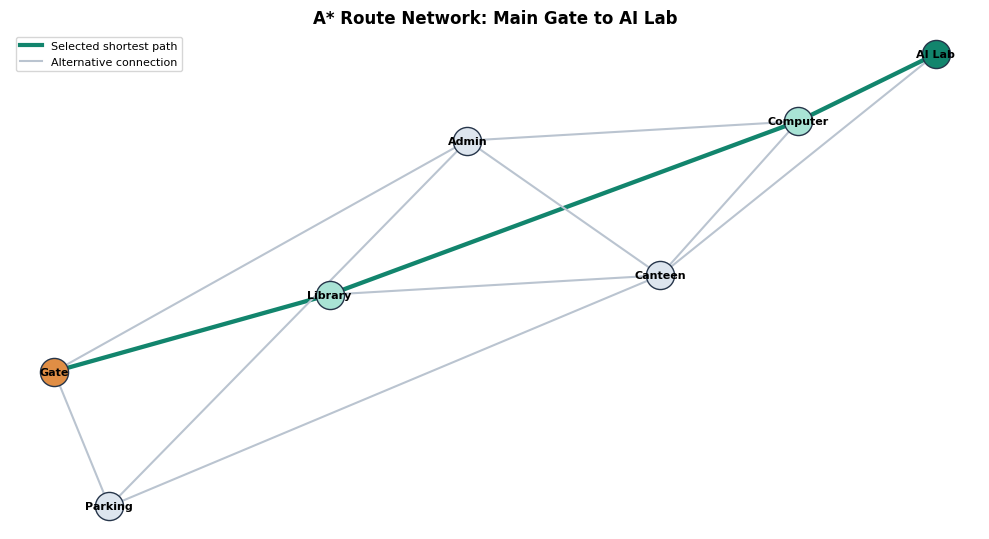

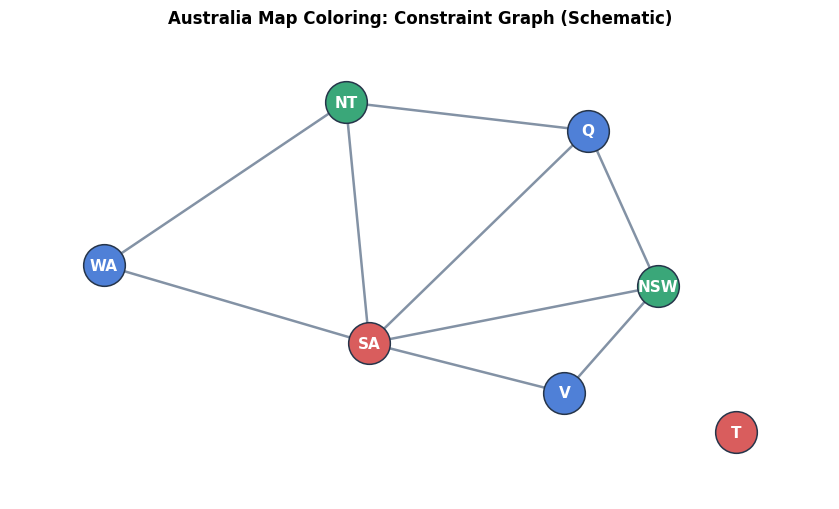

In [5]:
import math
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# A* route network
fig, ax = plt.subplots(figsize=(10, 5.5))
selected_edges = {frozenset((path[i], path[i + 1])) for i in range(len(path) - 1)}
for u, v, weight in ROUTE_EDGES:
    x1, y1 = POSITIONS[u]
    x2, y2 = POSITIONS[v]
    chosen = frozenset((u, v)) in selected_edges
    ax.plot([x1, x2], [y1, y2], color="#12856D" if chosen else "#BAC4D0",
            linewidth=3.1 if chosen else 1.5, zorder=1)
short_names = {"Main Gate":"Gate", "Library":"Library", "Admin Block":"Admin",
               "Parking":"Parking", "Canteen":"Canteen", "Computer Block":"Computer", "AI Lab":"AI Lab"}
for node, (x, y) in POSITIONS.items():
    node_color = "#E08E45" if node == source else ("#12856D" if node == destination else ("#A9E3D5" if node in path else "#DDE5EE"))
    ax.scatter([x], [y], s=410, c=[node_color], edgecolors="#26354A", linewidths=1.0, zorder=2)
    ax.text(x, y, short_names[node], ha="center", va="center", fontsize=8, fontweight="bold", zorder=3)
ax.legend(handles=[Line2D([0],[0], color="#12856D", linewidth=3, label="Selected shortest path"),
                   Line2D([0],[0], color="#BAC4D0", linewidth=1.5, label="Alternative connection")],
          loc="upper left", fontsize=8)
ax.set_title(f"A* Route Network: {source} to {destination}", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

# Australia constraint graph
map_layout = {"WA":(-2.0,0.1), "NT":(-0.45,1.25), "SA":(-0.30,-0.45),
              "Q":(1.1,1.05), "NSW":(1.55,-0.05), "V":(0.95,-0.80), "T":(2.05,-1.08)}
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for u in REGIONS:
    for v in ADJACENCY[u]:
        if REGIONS.index(u) < REGIONS.index(v):
            x1,y1=map_layout[u]; x2,y2=map_layout[v]
            ax.plot([x1,x2],[y1,y2], color="#8392A5", linewidth=1.8, zorder=1)
color_hex = {"Red":"#D95D5D", "Green":"#3AA779", "Blue":"#4F80D7"}
for region, (x,y) in map_layout.items():
    ax.scatter([x],[y],s=900,c=[color_hex[solution[region]]],edgecolors="#26354A",linewidths=1.1,zorder=2)
    ax.text(x,y,region,ha="center",va="center",color="white",fontweight="bold",fontsize=11,zorder=3)
ax.set_xlim(-2.6, 2.65); ax.set_ylim(-1.55,1.75)
ax.set_title("Australia Map Coloring: Constraint Graph (Schematic)", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

## Validation summary and conclusion

- A* finds a route of cost **400** for `Main Gate` → `AI Lab` and matches Dijkstra's result.
- The all-pairs comparison confirms equal shortest-path costs across all **49** endpoint combinations in this example graph.
- The 3-color map assignment passes all adjacency constraints.
- The 2-color case correctly returns no solution, demonstrating constraint-aware search and backtracking.

**Conclusion:** A* uses path cost plus an admissible heuristic to guide shortest-path search. Backtracking solves map coloring by extending partial assignments and undoing choices that lead to contradictions; MRV, degree ordering, LCV, and forward checking improve the search behavior.

**Complexity:** A* with a binary heap and a consistent heuristic is typically bounded by `O((V + E) log V)` for this finite graph-search setting, with `O(V + E)` graph/search storage. Map coloring has worst-case exponential time `O(k^n)` for `n` regions and `k` colors; with forward checking, the implementation stores domains and the current assignment in `O(nk)` auxiliary space.